# Fast Track AI

Desafio de analise de crédito

Informações e instruções sobre o desafio: https://github.com/LucasKiraly/fast-track-ia-t1/tree/main/desafios/analise-credito




## 🎯 Desafio

A equipe da CredAIR precisa utilizar o histórico de propostas para compreender melhor os fatores relacionados à inadimplência e investigar se é possível utilizar as informações disponíveis para apoiar a identificação de propostas de maior risco.

A partir dos dados fornecidos, desenvolva uma análise que percorra as principais etapas de um projeto de Ciência de Dados e Machine Learning.

Não existe uma única forma correta de realizar todas as etapas. Suas escolhas devem ser justificadas de acordo com o problema e com as características dos dados.

### 1. Entendimento do problema

Analise o contexto apresentado e as variáveis disponíveis.

Você deverá:

* identificar a **variável resposta** do problema;
* explicar o que essa variável representa;
* caracterizar o problema de Machine Learning;
* justificar por que o problema pode ser tratado como um problema de **classificação**.

## Resposta para o entendimento do problema:

- A CredAIR quer avaliar os fatores de inadimplência dos clientes para identificar propostas de crédito com maior risco.
- **Variável resposta (target):** `inadimplente`, onde `0` indica proposta que não resultou em inadimplência e `1` indica proposta que resultou em inadimplência.
- **Variáveis preditoras (features):** informações cadastrais, financeiras e características do empréstimo disponíveis no momento da proposta.
- **Tipo de aprendizado:** supervisionado, pois possuímos exemplos históricos com rótulo conhecido.
- **Por que o problema pode ser tratado como "Problema de Classificação"?** O problema pode ser de classificação porque queremos identificar uma de duas classes, se inadimplênte ou se adimplente. A Regressão Logística também estima a probabilidade associada à classe `1`, que consideramos como inadimplênte.

### 2. Análise exploratória

Investigue os dados antes de realizar a modelagem.

Sua análise deverá:

2.1 apresentar as principais características dos dados;
2.2 analisar a distribuição da variável resposta;
2.3 investigar relações entre as variáveis e a inadimplência;
2.4 destacar padrões ou comportamentos relevantes encontrados durante a análise.

Utilize tabelas, estatísticas e visualizações quando forem relevantes para sustentar suas conclusões.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True})
pd.set_option("display.max_columns", 30)

df_bruto = pd.read_csv("../dados/credito.csv")

print(f"Dimensões: {df_bruto.shape[0]:,} registros x {df_bruto.shape[1]} colunas")

print("5 primeiras linhas do arquivo 'credito.csv'")
display(df_bruto.head())

Dimensões: 5,000 registros x 11 colunas
5 primeiras linhas do arquivo 'credito.csv'


,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
0,52,MS,Ensino Superior,2911.82,14,690,5934.19,60,Viagem,1,0
1,49,RR,Ensino Médio,3176.43,5,676,6791.38,24,Outros,2,0
2,48,AL,Ensino Superior,3429.40,23,558,14666.78,24,Outros,5,1
3,59,GO,Ensino Fundamental,10096.70,2,739,19053.24,24,Reforma,0,0
4,37,RJ,Ensino Fundamental,3033.25,24,797,6171.31,6,Educação,0,1


Principais características dos dados:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   idade               5000 non-null   int64  
 1   estado              5000 non-null   str    
 2   escolaridade        5000 non-null   str    
 3   renda_mensal        5000 non-null   float64
 4   tempo_emprego_anos  5000 non-null   int64  
 5   score_credito       5000 non-null   int64  
 6   valor_solicitado    5000 non-null   float64
 7   prazo_meses         5000 non-null   int64  
 8   finalidade          5000 non-null   str    
 9   dividas_ativas      5000 non-null   int64  
 10  inadimplente        5000 non-null   int64  
dtypes: float64(2), int64(6), str(3)
memory usage: 429.8 KB
None


### 2.1 Tipos, preenchimento e estatísticas

O método `info()` revela o tipo inferido pelo Pandas e quantos valores não nulos existem.

In [8]:
df_bruto.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   idade               5000 non-null   int64  
 1   estado              5000 non-null   str    
 2   escolaridade        5000 non-null   str    
 3   renda_mensal        5000 non-null   float64
 4   tempo_emprego_anos  5000 non-null   int64  
 5   score_credito       5000 non-null   int64  
 6   valor_solicitado    5000 non-null   float64
 7   prazo_meses         5000 non-null   int64  
 8   finalidade          5000 non-null   str    
 9   dividas_ativas      5000 non-null   int64  
 10  inadimplente        5000 non-null   int64  
dtypes: float64(2), int64(6), str(3)
memory usage: 429.8 KB


O método `describe()` mostra estatísticas como média, quartis e extremos. Ausência de valores nulos **não** garante ausência de erros.

In [10]:
df_bruto.describe()

,idade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,dividas_ativas,inadimplente
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,47.767400,5228.633582,12.662200,652.481200,14264.657378,29.922000,1.900400,0.344000
std,31.646099,3968.478198,7.517539,84.817076,8268.261465,15.482515,1.864719,0.475089
min,18.000000,100.000000,1.000000,335.000000,1721.480000,6.000000,0.000000,0.000000
25%,32.000000,2697.320000,6.000000,594.000000,8467.170000,18.000000,0.000000,0.000000
50%,46.000000,4146.300000,13.000000,653.000000,12365.630000,24.000000,1.000000,0.000000
75%,61.000000,6458.877500,19.000000,710.000000,17764.885000,36.000000,3.000000,1.000000
max,750.000000,44814.190000,74.000000,850.000000,50000.000000,60.000000,7.000000,1.000000


### 2.2 Distribuição da resposta

A média de uma coluna com valores 0 e 1 é igual à proporção de registros com valor 1. É importante conhecer o desequilíbrio entre classes, porque um modelo que sempre prevê a classe majoritária pode obter boa acurácia sem detectar inadimplência.

Quantidade por classe:
inadimplente
0    3280
1    1720
Name: count, dtype: int64
Taxa de inadimplência: 34.40%


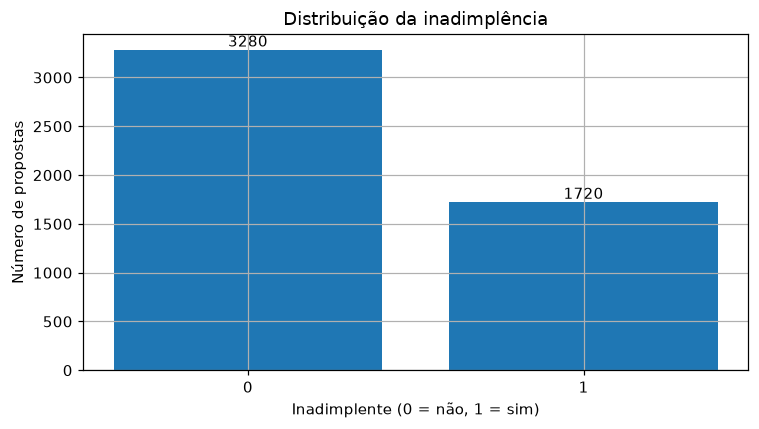

In [11]:
distribuicao = df_bruto["inadimplente"].value_counts().sort_index()
print("Quantidade por classe:")
print(distribuicao)
print(f"Taxa de inadimplência: {df_bruto['inadimplente'].mean():.2%}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(distribuicao.index.astype(str), distribuicao.values)
ax.set(title="Distribuição da inadimplência", xlabel="Inadimplente (0 = não, 1 = sim)", ylabel="Número de propostas")
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
plt.tight_layout()
plt.show()

### 2.3 Relações iniciais entre as variáveis e a inadimplência

Comparamos grupos de clientes, **sem afirmar causalidade**. Por exemplo, um score médio menor entre inadimplentes não prova que o score *causou* a inadimplência.

In [13]:
comparacao = df_bruto.groupby("inadimplente").agg(
    propostas=("inadimplente", "size"),
    score_medio=("score_credito", "mean"),
    renda_mediana=("renda_mensal", "median"),
    dividas_media=("dividas_ativas", "mean")
).round(2)
display(comparacao)

,propostas,score_medio,renda_mediana,dividas_media
inadimplente,,,,
0,3280,671.02,4606.35,1.67
1,1720,617.13,3330.64,2.34
